# Template Mahasiswa — Proyek Gingerbread
**Revisi: 22 Oktober 2026**

Notebook ini menyediakan pemuatan data, visualisasi, konversi anotasi, evaluasi, dan ekspor CSV. Algoritme deteksi, klasifikasi, dan penghitungan harus diimplementasikan mahasiswa dengan **non-deep learning dan deep learning** untuk kedua tugas.

- **Tugas 1:** prediksi sempurna/cacat; cacat = kelas positif (1).
- **Tugas 2:** jumlah seluruh gingerbread dan jumlah cacat per sisi. Khusus leaderboard: jumlah desain unik per sisi.
- Satu baris per citra. Tugas 2: **7 kolom** untuk tugas utama atau **10 kolom** untuk leaderboard.
- Desain cacat tetap termasuk desain asalnya. Desain unik dihitung secara terpisah pada setiap sisi.

Jalankan sel berurutan. Sel inferensi dinonaktifkan sampai fungsi mahasiswa selesai. Tidak ada prediksi atau hasil evaluasi contoh yang dipresentasikan sebagai hasil metode.

## 1. Persiapan dan konfigurasi

In [ ]:
import importlib.util, subprocess, sys
required = {'numpy':'numpy', 'pandas':'pandas', 'PIL':'Pillow', 'matplotlib':'matplotlib', 'sklearn':'scikit-learn', 'gdown':'gdown'}
missing = [pkg for module, pkg in required.items() if importlib.util.find_spec(module) is None]
if missing:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *missing])
import json, zipfile, hashlib
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from sklearn.metrics import confusion_matrix, precision_score, recall_score, f1_score, balanced_accuracy_score

DATA_URL = 'https://drive.google.com/file/d/1M1IRpFds1VyIkc9IJBehrprcjAEaPXSw/view?usp=sharing'
# Isi LOCAL_ZIP untuk ZIP yang diunggah sendiri, atau DATA_DIR untuk folder yang telah diekstrak.
LOCAL_ZIP = ''
DATA_DIR = ''
WORK_DIR = Path('/content/gingerbread_project')
LEADERBOARD = False  # True: tambahkan tiga kolom jumlah desain unik
EVAL_SPLIT = 'test'  # gunakan 'val' saat pengembangan; 'hidden' untuk data tanpa label
RUN_PREDICTIONS = False
SEED = 2026
np.random.seed(SEED)
FACES = ('front', 'right', 'top')
SINGLE_COLS = ['image_id', 'is_defective', 'defect_score']
def cube_columns(leaderboard=False):
    fields = ['total', 'defective'] + (['design_count'] if leaderboard else [])
    return ['image_id'] + [f'{face}_{field}' for field in fields for face in FACES]
CUBE_COLS = cube_columns(LEADERBOARD)
print('Kolom Tugas 2:', CUBE_COLS)

Kolom Tugas 2: ['image_id', 'front_total', 'right_total', 'top_total', 'front_defective', 'right_defective', 'top_defective']


## 2. Unduh dan ekstrak data
Dataset harus dapat diakses melalui tautan. Jika unduhan Drive gagal, unduh ZIP secara manual lalu isi `LOCAL_ZIP`. Untuk hidden dataset, gunakan ZIP siswa yang hanya berisi citra dan referensi. Jangan gunakan ZIP instruktur.

Ekstraksi menggunakan hash ZIP agar dataset berbeda tidak tercampur.

In [ ]:
def resolve_root(folder):
    candidates = [folder] + [p for p in folder.rglob('references') if p.is_dir()]
    roots = []
    for p in candidates:
        r = p.parent if p.name == 'references' else p
        if (r/'references').is_dir() and ((r/'single').is_dir() or (r/'cube').is_dir()):
            roots.append(r.resolve())
    roots = sorted(set(roots))
    if len(roots) != 1:
        raise ValueError(f'Harus ada satu root dataset, ditemukan: {roots}')
    return roots[0]

def prepare_data():
    if DATA_DIR:
        return resolve_root(Path(DATA_DIR))
    WORK_DIR.mkdir(parents=True, exist_ok=True)
    if LOCAL_ZIP:
        archive = Path(LOCAL_ZIP)
    else:
        import gdown
        key = hashlib.sha256(DATA_URL.encode()).hexdigest()[:12]
        archive = WORK_DIR/f'dataset_{key}.zip'
        if not archive.exists() or not zipfile.is_zipfile(archive):
            gdown.download(url=DATA_URL, output=str(archive), fuzzy=True, quiet=False)
    if not zipfile.is_zipfile(archive):
        raise ValueError('Berkas bukan ZIP yang valid. Gunakan unduhan manual melalui LOCAL_ZIP.')
    digest = hashlib.sha256(archive.read_bytes()).hexdigest()[:16]
    folder = WORK_DIR/f'extracted_{digest}'
    if not (folder/'.complete').exists():
        folder.mkdir(parents=True, exist_ok=True)
        with zipfile.ZipFile(archive) as z:
            for name in z.namelist():
                target = (folder/name).resolve()
                if not target.is_relative_to(folder.resolve()):
                    raise ValueError('ZIP memuat path di luar folder ekstraksi.')
            z.extractall(folder)
        (folder/'.complete').touch()
    return resolve_root(folder)

ROOT = prepare_data()
print('Root dataset:', ROOT)

Downloading...
From (original): https://drive.google.com/uc?id=1M1IRpFds1VyIkc9IJBehrprcjAEaPXSw
From (redirected): https://drive.google.com/uc?id=1M1IRpFds1VyIkc9IJBehrprcjAEaPXSw&confirm=t&uuid=0539e710-5eda-4acc-8773-c1d4d087df7b
To: /content/gingerbread_project/dataset_ffe4c068449a.zip
100%|██████████| 138M/138M [00:04<00:00, 33.2MB/s]


Root dataset: /content/gingerbread_project/extracted_b51c235305ee4494


## 3. Indeks citra, referensi, dan konversi label

In [ ]:
def read_rgb(path):
    with Image.open(path) as im:
        return np.asarray(im.convert('RGB'))

def read_mask(path):
    # Pertahankan ID integer pada mask instance; jangan konversi menjadi RGB/uint8.
    with Image.open(path) as im:
        return np.asarray(im).copy()

def image_index(root, task):
    records = []
    for path in sorted((root/task).rglob('*')):
        if path.is_file() and path.parent.name == 'images' and path.suffix.lower() in {'.png','.jpg','.jpeg'}:
            records.append({'image_id':path.stem, 'split':path.parent.parent.name,
                            'image_path':str(path), 'task':task})
    out = pd.DataFrame(records, columns=['image_id','split','image_path','task'])
    if out.image_id.duplicated().any():
        raise ValueError(f'ID citra duplikat pada {task}. Jangan gabungkan dataset tanpa mengganti ID.')
    return out

def load_references(root):
    records = json.loads((root/'references/designs.json').read_text())
    refs = {}
    for item in records:
        path = root/'references'/item['reference_file']
        with Image.open(path) as im:
            rgba = np.asarray(im.convert('RGBA'))
        refs[int(item['design_id'])] = {'name':item['name'], 'rgba':rgba,
                                      'mask':rgba[:,:,3] > 0}
    return refs

def parse_bool(x):
    text = str(x).strip().lower()
    if text not in {'true','false','1','0'}:
        raise ValueError(f'Label biner tidak dikenal: {x}')
    return int(text in {'true','1'})

def load_single_labels(root):
    path = root/'single_labels.csv'
    if not path.exists():
        return None
    df = pd.read_csv(path, dtype={'id':str, 'image_id':str}).rename(columns={'id':'image_id'})
    df['is_defective'] = df.is_defective.map(parse_bool)
    if df.image_id.duplicated().any():
        raise ValueError('Label single duplikat.')
    return df

def load_cube_labels(root):
    path = root/'cube_face_labels.csv'
    if not path.exists():
        return None
    old = pd.read_csv(path, dtype={'image_id':str})
    if old.duplicated(['image_id','face']).any():
        raise ValueError('Label sisi duplikat.')
    rows = []
    for image_id, group in old.groupby('image_id', sort=False):
        if set(group.face) != set(FACES) or group['split'].nunique() != 1:
            raise ValueError(f'Label tiga sisi tidak lengkap: {image_id}')
        row = {'image_id':image_id, 'split':group['split'].iloc[0]}
        for _, item in group.iterrows():
            counts = json.loads(item.counts_by_design)
            defects = json.loads(item.defective_counts_by_design)
            total, bad = sum(counts.values()), sum(defects.values())
            if total != item.total_instances or not 0 <= bad <= total:
                raise ValueError(f'Anotasi tidak konsisten: {image_id}')
            face = item.face
            row.update({f'{face}_total':int(total), f'{face}_defective':int(bad),
                        f'{face}_design_count':sum(int(n)>0 for n in counts.values())})
        rows.append(row)
    return pd.DataFrame(rows, columns=['image_id','split'] + cube_columns(True)[1:])

single_index = image_index(ROOT, 'single')
cube_index = image_index(ROOT, 'cube')
references = load_references(ROOT)
single_labels = load_single_labels(ROOT)
cube_labels = load_cube_labels(ROOT)
for task, index, labels in [('single',single_index,single_labels), ('cube',cube_index,cube_labels)]:
    print(task, index.groupby('split').size().to_dict(), 'label tersedia:', labels is not None)
print('Desain tersedia:', {k:v['name'] for k,v in references.items()})
if cube_labels is not None:
    display(cube_labels.head())

single {'test': 30, 'train': 140, 'val': 30} label tersedia: True
cube {'test': 15, 'train': 70, 'val': 15} label tersedia: True
Desain tersedia: {1: 'blue_wizard'}


,image_id,split,front_total,right_total,top_total,front_defective,right_defective,top_defective,front_design_count,right_design_count,top_design_count
0,cube_000000,test,2,3,1,1,1,0,1,1,1
1,cube_000001,train,1,3,2,0,1,0,1,1,1
2,cube_000002,test,1,3,2,0,1,0,1,1,1
3,cube_000003,train,2,1,3,0,0,0,1,1,1
4,cube_000004,val,2,1,3,0,0,2,1,1,1


## 4. Visualisasi referensi dan citra
Label ditampilkan hanya jika tersedia. Pada hidden dataset tidak ada label yang diasumsikan atau diisi otomatis. Visualisasi anotasi hanya untuk eksplorasi data berlabel.

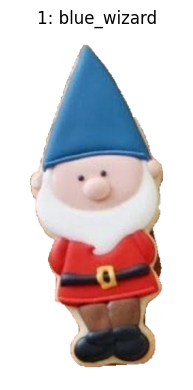

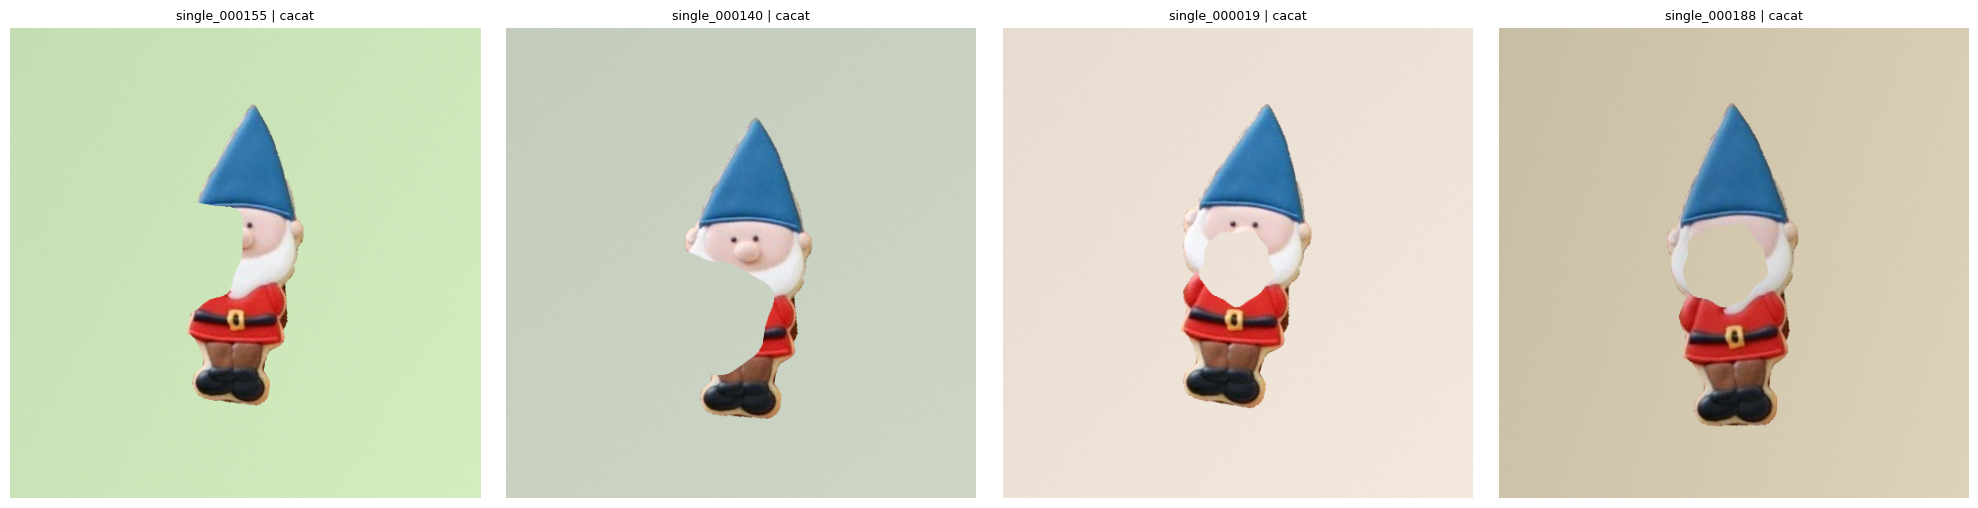

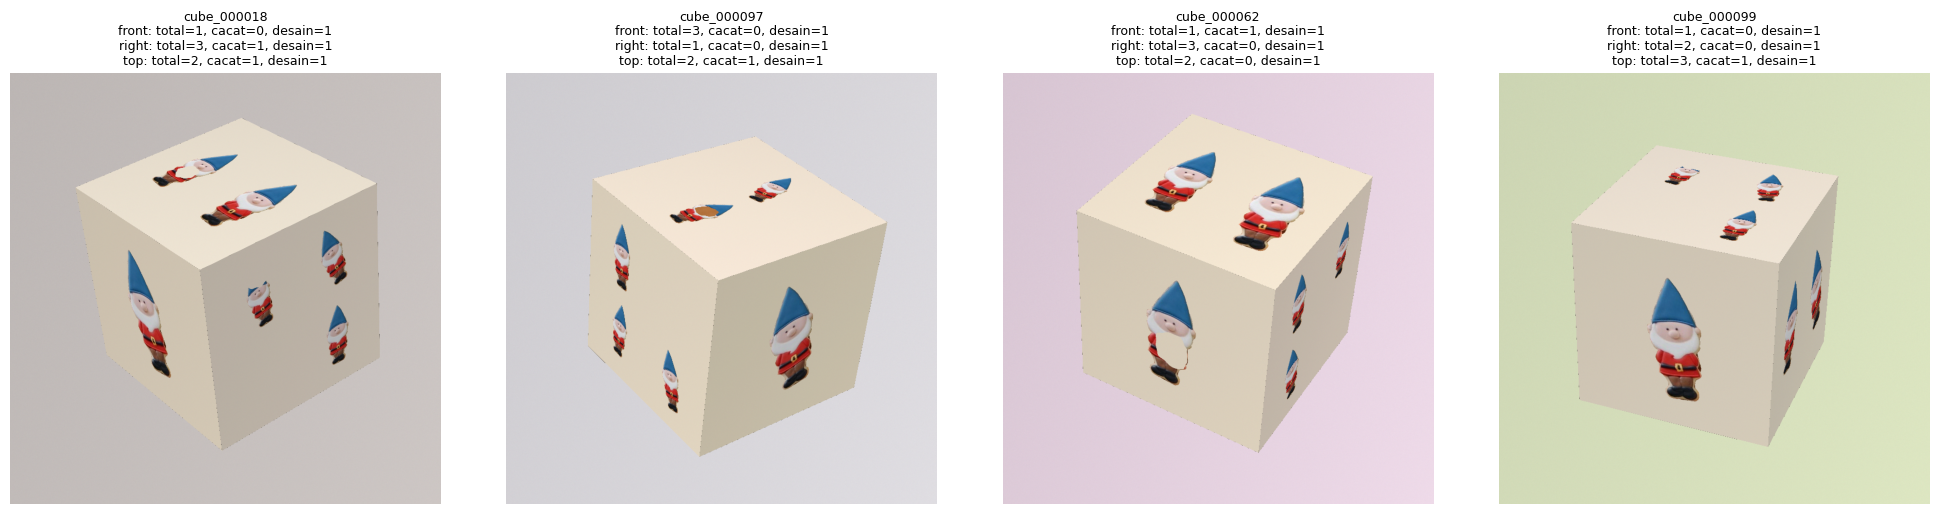

In [ ]:
fig, axes = plt.subplots(1, len(references), figsize=(3*len(references),4), squeeze=False)
for ax, (design_id, ref) in zip(axes.ravel(), references.items()):
    ax.imshow(ref['rgba']); ax.set_title(f"{design_id}: {ref['name']}"); ax.axis('off')
plt.tight_layout(); plt.show()

def visualize_samples(index, labels=None, n=4, split='train'):
    subset = index[index['split'].eq(split)]
    if subset.empty:
        print(f'Tidak ada citra pada split {split}.'); return
    subset = subset.sample(min(n,len(subset)), random_state=SEED)
    fig, axes = plt.subplots(1,len(subset),figsize=(5*len(subset),5),squeeze=False)
    targets = {} if labels is None else labels.set_index('image_id').to_dict('index')
    for ax, row in zip(axes.ravel(), subset.itertuples()):
        ax.imshow(read_rgb(row.image_path)); ax.axis('off')
        title = row.image_id
        y = targets.get(row.image_id)
        if y is not None:
            if row.task == 'single':
                title += ' | cacat' if y['is_defective'] else ' | sempurna'
            else:
                title += '\n' + '\n'.join(f"{f}: total={y[f+'_total']}, cacat={y[f+'_defective']}, desain={y[f+'_design_count']}" for f in FACES)
        ax.set_title(title,fontsize=9)
    plt.tight_layout(); plt.show()

visualize_samples(single_index, single_labels)
visualize_samples(cube_index, cube_labels)

## 5. Data untuk pengembangan
Gunakan `train` untuk melatih metode dan `val` untuk memilih parameter/threshold. Gunakan `test` untuk evaluasi akhir. Jangan mengubah split berdasarkan hasil uji. Dataset satu desain belum cukup untuk menguji penghitungan desain unik.

Dataframe di bawah menyimpan path citra dan target. Muat citra sesuai kebutuhan agar penggunaan RAM terkontrol. Anotasi tambahan tersedia di folder `annotations` dan `masks`; tidak boleh digunakan sebagai masukan saat inferensi.

In [ ]:
def labeled_split(index, labels, split):
    images = index[index['split'].eq(split)].copy()
    if labels is None:
        raise ValueError('Dataset ini tidak memiliki label.')
    out = images.merge(labels.drop(columns=['split','image'],errors='ignore'), on='image_id', how='left', validate='one_to_one', indicator=True)
    if not out['_merge'].eq('both').all():
        raise ValueError('Ada citra yang tidak memiliki label.')
    return out.drop(columns='_merge')

single_train = labeled_split(single_index, single_labels, 'train') if single_labels is not None else None
single_val = labeled_split(single_index, single_labels, 'val') if single_labels is not None else None
cube_train = labeled_split(cube_index, cube_labels, 'train') if cube_labels is not None else None
cube_val = labeled_split(cube_index, cube_labels, 'val') if cube_labels is not None else None
# Contoh akses: image = read_rgb(single_train.iloc[0].image_path)
# TODO: ekstraksi fitur, augmentasi train, DataLoader, pelatihan, dan pemilihan parameter.
# Terapkan transformasi geometri secara konsisten pada citra dan label spasial bila digunakan.

## 6. Implementasi mahasiswa
Isi keempat fungsi berikut. Fungsi inferensi hanya menerima **citra RGB dan referensi**; model yang telah dilatih dapat diakses dari variabel atau objek model Anda.

- Tugas 1: kembalikan `is_defective` (0/1) dan `defect_score` (0–1, semakin tinggi semakin cacat). Tetapkan threshold berdasarkan validasi.
- Tugas 2: kembalikan dict dengan enam hitungan; tambahkan tiga `*_design_count` saat leaderboard aktif. Semua hitungan berupa integer nonnegatif.
- Referensi menggunakan ID asli dan dapat bertambah dari satu menjadi tujuh desain. Jangan mengasumsikan ID berurutan atau jumlah objek yang selalu sama.

SIFT/feature matching, RANSAC, segmentasi, dan pembelajaran fitur dapat digunakan sesuai pendekatan. Notebook ini tidak menyediakan implementasi baseline.

In [ ]:
def predict_single_non_dl(rgb, references):
    raise NotImplementedError('TODO: metode non-deep learning Tugas 1')

def predict_single_dl(rgb, references):
    raise NotImplementedError('TODO: metode deep learning Tugas 1')

def predict_cube_non_dl(rgb, references):
    # Format: {'front_total': ..., 'right_total': ..., 'top_total': ...,
    #          'front_defective': ..., 'right_defective': ..., 'top_defective': ...}
    # Leaderboard: tambahkan front_design_count, right_design_count, top_design_count.
    raise NotImplementedError('TODO: metode non-deep learning Tugas 2')

def predict_cube_dl(rgb, references):
    raise NotImplementedError('TODO: metode deep learning Tugas 2')

## 7. Validasi prediksi dan evaluasi

In [ ]:
def validate_predictions(pred, expected_ids, task, leaderboard=False):
    cols = SINGLE_COLS if task == 'single' else cube_columns(leaderboard)
    if list(pred.columns) != cols:
        raise ValueError(f'Nama/urutan kolom wajib: {cols}')
    if pred.image_id.isna().any() or pred.image_id.duplicated().any():
        raise ValueError('ID kosong atau duplikat.')
    if set(pred.image_id) != set(expected_ids) or len(pred) != len(expected_ids):
        raise ValueError('ID hilang atau berlebih dibanding daftar citra.')
    values = pred[cols[1:]].to_numpy(dtype=float)
    if not np.isfinite(values).all():
        raise ValueError('Prediksi memuat NaN/inf.')
    if task == 'single':
        if not pred.is_defective.isin([0,1]).all() or not pred.defect_score.between(0,1).all():
            raise ValueError('Label harus 0/1; defect_score harus 0–1.')
    else:
        if (values < 0).any() or not np.equal(values,np.floor(values)).all():
            raise ValueError('Hitungan wajib integer nonnegatif.')
        for f in FACES:
            if (pred[f+'_defective'] > pred[f+'_total']).any():
                raise ValueError('Jumlah cacat melebihi jumlah total.')
            if leaderboard:
                d,t = pred[f+'_design_count'],pred[f+'_total']
                if ((d>t)|(d>len(references))|((t>0)&(d==0))).any():
                    raise ValueError('Jumlah desain unik tidak konsisten.')
    return pred

def aligned_targets(pred, truth, cols):
    if truth is None:
        raise ValueError('Evaluasi tidak tersedia: hidden dataset tidak memiliki label.')
    if truth.image_id.duplicated().any():
        raise ValueError('ID ground truth duplikat.')
    indexed = truth.set_index('image_id')
    missing = set(pred.image_id)-set(indexed.index)
    if missing:
        raise ValueError(f'Ground truth tidak tersedia untuk {len(missing)} citra.')
    return indexed.loc[pred.image_id,cols].to_numpy(dtype=float)

def evaluate_single(pred, truth):
    y = aligned_targets(pred, truth, ['is_defective']).ravel().astype(int)
    p = pred.is_defective.to_numpy(dtype=int)
    return {'precision':precision_score(y,p,zero_division=0),
            'recall':recall_score(y,p,zero_division=0),
            'f1':f1_score(y,p,zero_division=0),
            'balanced_accuracy':balanced_accuracy_score(y,p) if len(np.unique(y))==2 else np.nan,
            'confusion_matrix_labels_0_1':confusion_matrix(y,p,labels=[0,1]).tolist()}

def evaluate_cube(pred, truth, leaderboard=False):
    fields = ['total','defective'] + (['design_count'] if leaderboard else [])
    cols = cube_columns(leaderboard)[1:]
    y = aligned_targets(pred,truth,cols)
    p = pred[cols].to_numpy(dtype=float)
    if len(p)==0:
        raise ValueError('Tidak ada prediksi untuk dievaluasi.')
    # Kolom diurutkan field dahulu, lalu face: N × K × 3.
    errors = np.abs(p-y).reshape(len(p),len(fields),3)
    result = {}
    for k, field in enumerate(fields):
        result['mae_'+field] = float(errors[:,k,:].mean())
        for j, face in enumerate(FACES):
            result[f'mae_{face}_{field}'] = float(errors[:,k,j].mean())
    result['exact_match_face_pct'] = float((errors==0).all(axis=1).mean()*100)
    result['exact_match_image_pct'] = float((errors==0).all(axis=(1,2)).mean()*100)
    bad_truth = y.reshape(len(p),len(fields),3)[:,1,:]
    positive = bad_truth > 0
    result['mae_defective_on_defective_faces'] = float(errors[:,1,:][positive].mean()) if positive.any() else None
    return result

MAE dihitung terpisah untuk setiap target dengan rata-rata seluruh citra dan sisi. Exact match tugas utama memeriksa 2 nilai per sisi atau 6 nilai per citra. Pada leaderboard, masing-masing menjadi 3 dan 9 nilai. Metrik peringkat leaderboard belum ditetapkan; fungsi ini tidak mengasumsikan skor gabungan.

MAE cacat pada sisi yang memang cacat membantu memeriksa apakah metode hanya memprediksi nol. Balanced accuracy dilaporkan NaN apabila data evaluasi hanya memuat satu kelas.

## 8. Jalankan inferensi, evaluasi, dan simpan CSV

In [ ]:
def run_inference(index, predictor, task, leaderboard=False):
    cols = SINGLE_COLS if task == 'single' else cube_columns(leaderboard)
    if index.empty:
        raise ValueError('Split yang dipilih tidak memiliki citra.')
    records = []
    for row in index.itertuples():
        result = predictor(read_rgb(row.image_path), references)
        if not isinstance(result,dict) or set(result) != set(cols[1:]):
            raise ValueError(f'Fungsi harus mengembalikan dict dengan kunci {cols[1:]}')
        records.append({'image_id':row.image_id, **result})
    pred = pd.DataFrame(records,columns=cols)
    validate_predictions(pred,index.image_id.tolist(),task,leaderboard)
    return pred

OUTPUT_DIR = WORK_DIR/'outputs'
OUTPUT_DIR.mkdir(parents=True,exist_ok=True)
metrics = {}
if RUN_PREDICTIONS:
    methods = [('single_non_dl','single',predict_single_non_dl),
               ('single_dl','single',predict_single_dl),
               ('cube_non_dl','cube',predict_cube_non_dl),
               ('cube_dl','cube',predict_cube_dl)]
    for name, task, predictor in methods:
        index = single_index if task=='single' else cube_index
        chosen = index[index['split'].eq(EVAL_SPLIT)]
        pred = run_inference(chosen,predictor,task,LEADERBOARD)
        path = OUTPUT_DIR/f'{name}_{EVAL_SPLIT}.csv'
        pred.to_csv(path,index=False)
        print('Tersimpan:',path)
        truth = single_labels if task=='single' else cube_labels
        if truth is not None and set(pred.image_id).issubset(set(truth.image_id)):
            metrics[name] = evaluate_single(pred,truth) if task=='single' else evaluate_cube(pred,truth,LEADERBOARD)
    display(pd.DataFrame(metrics).T)
else:
    print('Isi empat fungsi mahasiswa, kemudian ubah RUN_PREDICTIONS=True dan jalankan ulang sel ini.')

Isi empat fungsi mahasiswa, kemudian ubah RUN_PREDICTIONS=True dan jalankan ulang sel ini.


## 9. Template CSV dan unduhan
Template berikut berisi **kolom prediksi kosong**, bukan jawaban dan bukan submission valid. Isi melalui metode Anda sebelum dikumpulkan. Gunakan ID dan urutan dari sample submission resmi.

In [ ]:
for task,index in [('single',single_index),('cube',cube_index)]:
    chosen = index[index['split'].eq(EVAL_SPLIT)]
    cols = SINGLE_COLS if task=='single' else cube_columns(LEADERBOARD)
    template = pd.DataFrame({'image_id':chosen.image_id.tolist()}).reindex(columns=cols)
    template.to_csv(OUTPUT_DIR/f'template_{task}_{EVAL_SPLIT}.csv',index=False)
print('Folder keluaran:',OUTPUT_DIR)
# Unduh satu berkas setelah dihasilkan:
# from google.colab import files
# files.download(str(OUTPUT_DIR / f'cube_non_dl_{EVAL_SPLIT}.csv'))

Folder keluaran: /content/gingerbread_project/outputs


## 10. Checklist laporan
- Bandingkan non-deep learning dan deep learning pada pembagian data yang sama.
- Laporkan metrik Tugas 1 dan Tugas 2 secara terpisah, termasuk hasil per sisi.
- Tampilkan contoh berhasil/gagal, jenis dan tingkat cacat, serta pengaruh perspektif.
- Bahas generalisasi desain; jumlah desain unik pada data satu desain selalu satu.
- Catat parameter, threshold, seed, versi pustaka, waktu inferensi, dan perangkat.
- Gunakan hanya citra, referensi yang diizinkan, serta model terlatih saat inferensi hidden.
- Jangan memakai ID/nama berkas atau pola jumlah objek pada dataset sebagai jalan pintas prediksi.